# Phishing Detection with Random Forest

**Goal:** classify legitimate websites (`0`) vs phishing websites (`1`), compare a baseline Random Forest with GridSearchCV and Optuna, evaluate reliably, and save a reusable model artifact.

## 1. Imports and configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import time
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict, learning_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
import optuna

RANDOM_STATE = 42
N_SPLITS = 5
OPTUNA_TRIALS = 30
TARGET = "target"
LABEL_NAMES = ["Legitimate", "Phishing"]

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 2. Data and output folders
The data is read from the `processed` folder inside the parent folder of the notebook's working directory (`PROJECT_ROOT`). The `models` folder is created in the same parent folder, and the saved model files go there. If the notebook is launched from a different working directory, adjust `PROJECT_ROOT` or `DATA_FOLDER` manually.

In [2]:
PROJECT_ROOT = Path.cwd().parent
DATA_FOLDER = "processed"
DATA_DIR = PROJECT_ROOT / DATA_FOLDER

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

print("Data folder:", DATA_DIR)
print("Model folder:", MODEL_DIR)

Data folder: c:\Users\LENOVO\OneDrive\Desktop\processed
Model folder: c:\Users\LENOVO\OneDrive\Desktop\models


## 3. Load and validate the datasets

In [3]:
train_df = pd.read_csv(DATA_DIR / "preprocessed_train_pca.csv")
test_df = pd.read_csv(DATA_DIR / "preprocessed_test_pca.csv")

if train_df.empty or test_df.empty:
    raise ValueError("Training and test CSV files must not be empty.")

for name, df in [("training", train_df), ("test", test_df)]:
    if TARGET not in df.columns:
        raise ValueError(f"The {name} dataset is missing the target column '{TARGET}'.")
    if df.columns.duplicated().any():
        raise ValueError(f"The {name} dataset contains duplicate column names.")

x_train = train_df.drop(columns=TARGET).copy()
y_train = train_df[TARGET].copy()
x_test = test_df.drop(columns=TARGET).copy()
y_test = test_df[TARGET].copy()


x_test = x_test[x_train.columns]

if y_train.value_counts().min() < N_SPLITS:
    raise ValueError(f"Each training class needs at least {N_SPLITS} rows for CV.")

display(pd.DataFrame({
    "Training count": y_train.value_counts().reindex([0, 1]),
    "Training %": (y_train.value_counts(normalize=True).reindex([0, 1]) * 100).round(2),
    "Test count": y_test.value_counts().reindex([0, 1], fill_value=0),
    "Test %": (y_test.value_counts(normalize=True).reindex([0, 1]) * 100).round(2)
}).rename(index={0: "Legitimate", 1: "Phishing"}))

,Training count,Training %,Test count,Test %
target,,,,
Legitimate,22685,47.38,5672,47.39
Phishing,25190,52.62,6298,52.61


In [4]:
print(f"Train: {x_train.shape[0]} rows x {x_train.shape[1]} features")

Train: 47875 rows x 25 features


In [5]:
print(f"Test:  {x_test.shape[0]} rows x {x_test.shape[1]} features")

Test:  11970 rows x 25 features


In [6]:
print("Target labels: 0 = Legitimate, 1 = Phishing")

Target labels: 0 = Legitimate, 1 = Phishing


## 4. Data checks and visual exploration

In [7]:
print(f"Duplicate rows (train): {train_df.duplicated().sum()}")

Duplicate rows (train): 4540


In [8]:
print(f"Duplicate rows (test): {test_df.duplicated().sum()}\n")

Duplicate rows (test): 11



In [9]:
print(f"Rows with duplicated features across train/test:{len(set(map(tuple, x_train.to_numpy())) & set(map(tuple, x_test.to_numpy())))}")

Rows with duplicated features across train/test:70


In [10]:
print(train_df[train_df.duplicated()][TARGET].value_counts().rename(index={0: "Legitimate", 1: "Phishing"}))

target
Phishing      4470
Legitimate      70
Name: count, dtype: int64


In [11]:
labels_per_row = train_df.groupby(list(x_train.columns))[TARGET].nunique()
print("Identical feature rows with different labels:", int((labels_per_row > 1).sum()))

Identical feature rows with different labels: 0


### Note on duplicates
The checks above found **4,540 duplicate rows in the training set**, **11 in the test set**, and **70 feature vectors that appear in both train and test**. We keep them as they are, for these reasons:
- **Identical rows are not necessarily errors.** Different websites can share the same feature values, and repeated rows show how common a pattern is. Removing them could change the class balance and the weight of common patterns.
- **There is no sign that they inflate the results.** The test set has almost no duplicates and little overlap with the training data, and for all three models the test accuracy is slightly higher than the CV accuracy, not lower.
- **What the duplicates are:** almost all of the 4,540 extra copies in train are phishing rows (4,470 Phishing vs 70 Legitimate), and no group of identical rows has different labels, so the duplicates do not make the labels ambiguous. This means the training set repeats some phishing patterns many times, which gives them extra weight. The test set has almost no duplicates (11) and shares only 70 vectors with train, so its score is barely affected by repeated rows.

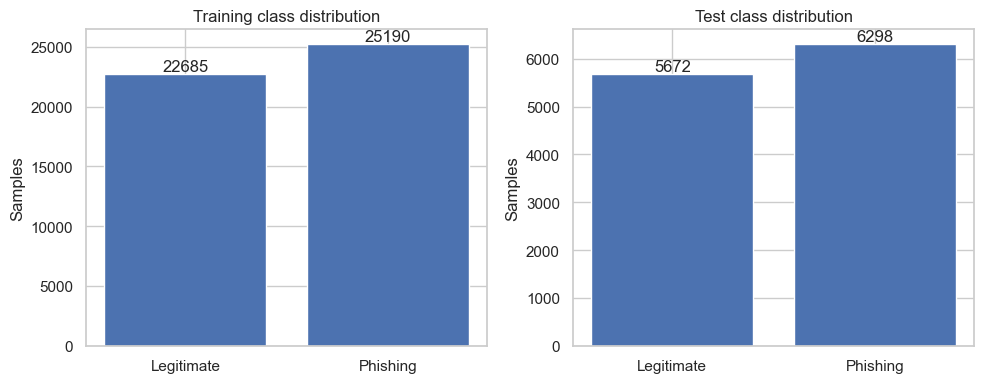

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, labels, title in [(axes[0], y_train, "Training class distribution"),(axes[1], y_test, "Test class distribution")]:
    counts = labels.value_counts().reindex([0, 1], fill_value=0)
    bars = ax.bar(["Legitimate", "Phishing"], counts.values)
    ax.bar_label(bars, fmt="%d")
    ax.set_title(title)
    ax.set_ylabel("Samples")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [13]:
display(train_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
PC01,47875.0,3.799456e-17,4.431768,-5.996059,-3.727373,-0.644873,2.351022,21.473947
PC02,47875.0,-3.461067e-16,3.921019,-11.502637,-2.562036,-0.558209,1.758884,10.946288
PC03,47875.0,7.598911e-17,2.507489,-7.452233,-1.656533,-0.062070,1.707945,14.150949
PC04,47875.0,1.959094e-16,2.283419,-13.298291,-1.240954,0.144572,1.559380,7.954430
PC05,47875.0,7.955110e-17,2.161351,-8.068477,-1.160920,-0.131266,0.987102,10.345227
PC06,47875.0,6.292848e-17,2.002008,-8.156803,-0.795688,0.025445,0.856775,15.704809
PC07,47875.0,-9.973571e-17,1.813665,-6.231141,-1.039307,-0.275772,0.648583,9.980093
PC08,47875.0,-1.899728e-17,1.670056,-7.971848,-1.041972,-0.062527,1.212080,6.744156
PC09,47875.0,-2.849592e-17,1.569014,-5.785595,-1.059043,-0.209360,0.961066,7.636538
PC10,47875.0,8.548775e-17,1.478638,-6.327616,-0.879524,0.006555,0.862968,8.754879


## 5. Cross-validation setup
All cross-validation steps use the same shuffled, stratified 5-fold splitter. The test set is reserved for final evaluation and should not guide hyperparameter choices.

In [14]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

## 6. Evaluation helpers

In [15]:
def get_metrics(model, x, y_real, name):
    """
    a function that returns a dictionary that contains all the metrics of a model.
    """
    pred = model.predict(x)
    prob = model.predict_proba(x)[:, 1]
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(y_true=y_real, y_pred=pred),4),
        "Balanced accuracy": round(balanced_accuracy_score(y_true=y_real, y_pred=pred),4),
        "Precision": round(precision_score(y_true=y_real, y_pred=pred, zero_division=0),4),
        "Recall": round(recall_score(y_true=y_real, y_pred=pred, zero_division=0),4),
        "F1": round(f1_score(y_true=y_real, y_pred=pred, zero_division=0),4),
        "ROC-AUC": round(roc_auc_score(y_true=y_real, y_score=prob),4),
        "Average precision": round(average_precision_score(y_true=y_real, y_score=prob),4)
    }

In [16]:
def evaluate_model(model, x, y_real, name):
    """
    a function that evaluates a model and displays the required visuals.
    """
    pred = model.predict(x)
    prob = model.predict_proba(x)[:, 1]
    metrics = get_metrics(model,x,y_real,name)

    for i in metrics.keys():
        print(f"{i}: {metrics[i]}\n")
    
    print(classification_report(y_real, pred, labels=[0, 1], target_names=LABEL_NAMES, zero_division=0,digits=4))

    cm = confusion_matrix(y_real, pred, labels=[0, 1])

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    sns.heatmap(cm, annot=True, fmt="d",cmap="Blues", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=axes[0])
    axes[0].set(title=f"Confusion matrix — {name}", xlabel="Predicted", ylabel="Actual")
    fpr, tpr, _ = roc_curve(y_real, prob, pos_label=1)
    axes[1].plot(fpr, tpr, label=f"AUC = {metrics['ROC-AUC']}")
    axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
    axes[1].set(title=f"ROC curve — {name}", xlabel="False positive rate", ylabel="True positive rate")
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

## 7. Baseline Random Forest

5-fold CV accuracy: 0.9931 ± 0.0007

Model: Baseline Random Forest

Accuracy: 0.9952

Balanced accuracy: 0.9952

Precision: 0.997

Recall: 0.9938

F1: 0.9954

ROC-AUC: 0.9992

Average precision: 0.9994

              precision    recall  f1-score   support

  Legitimate     0.9931    0.9967    0.9949      5672
    Phishing     0.9970    0.9938    0.9954      6298

    accuracy                         0.9952     11970
   macro avg     0.9951    0.9952    0.9951     11970
weighted avg     0.9952    0.9952    0.9952     11970



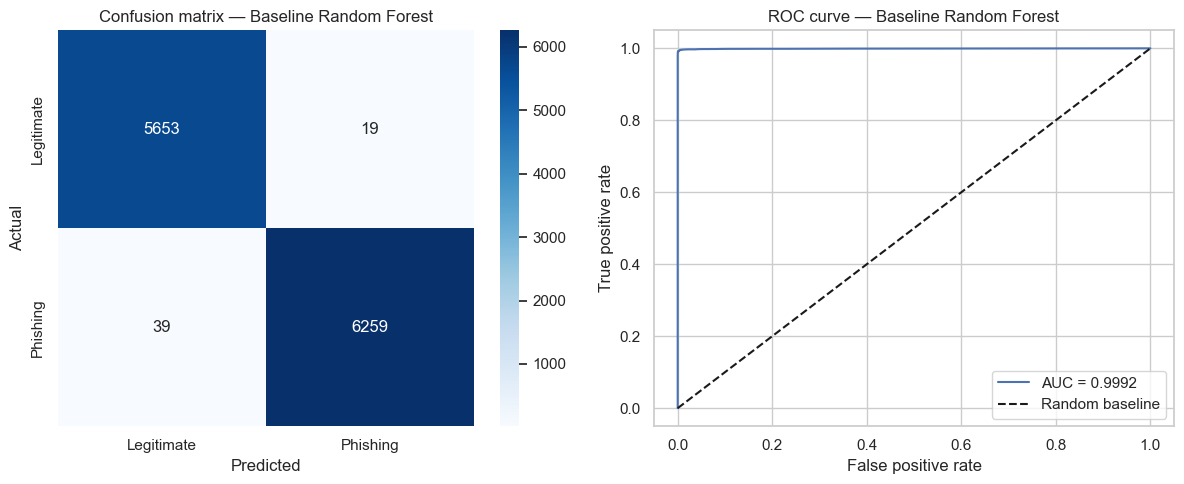

In [17]:
rf_baseline = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_baseline.fit(x_train, y_train)

baseline_cv = cross_val_score(rf_baseline,x_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)

print(f"5-fold CV accuracy: {round(baseline_cv.mean(),4)} ± {round(baseline_cv.std(),4)}\n")

evaluate_model(rf_baseline, x_test, y_test, "Baseline Random Forest")

## 8. Hyperparameter tuning with GridSearchCV
The grid has 216 combinations and each one is fitted 5 times (1,080 fits), which takes a very long time. For this reason the search cell below is **commented out**. The best parameters it found were copied into the "Tuned Random Forest" cell that follows.

In [18]:
'''
rf_params = {
    'n_estimators': [300,500],
    'criterion':['gini','entropy','log_loss'],
    'max_depth':[8, 12, 15],
    'min_samples_split':[10, 15, 20],
    'min_samples_leaf': [10, 15],
    'max_features': ['sqrt', 'log2'],
    'random_state': [42]
}

rf_grid = GridSearchCV(
    estimator=rf_baseline,
    param_grid=rf_params,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    error_score="raise",
    verbose=1
)

start = time.perf_counter()
rf_grid.fit(x_train, y_train)
grid_fit_time = time.perf_counter() - start
rf_tuned = rf_grid.best_estimator_

print(f"Best 5-fold CV accuracy: {round(rf_grid.best_score_,4)}")
print("Best parameters:", rf_grid.best_params_)
print(f"Search time: {round(grid_fit_time / 60,3)} minutes")

display(pd.DataFrame(rf_grid.cv_results_).sort_values("rank_test_score").head(5)[["rank_test_score", "mean_test_score", "std_test_score", "params"]])
'''

'\nrf_params = {\n    \'n_estimators\': [300,500],\n    \'criterion\':[\'gini\',\'entropy\',\'log_loss\'],\n    \'max_depth\':[8, 12, 15],\n    \'min_samples_split\':[10, 15, 20],\n    \'min_samples_leaf\': [10, 15],\n    \'max_features\': [\'sqrt\', \'log2\'],\n    \'random_state\': [42]\n}\n\nrf_grid = GridSearchCV(\n    estimator=rf_baseline,\n    param_grid=rf_params,\n    cv=cv,\n    scoring="accuracy",\n    n_jobs=-1,\n    refit=True,\n    error_score="raise",\n    verbose=1\n)\n\nstart = time.perf_counter()\nrf_grid.fit(x_train, y_train)\ngrid_fit_time = time.perf_counter() - start\nrf_tuned = rf_grid.best_estimator_\n\nprint(f"Best 5-fold CV accuracy: {round(rf_grid.best_score_,4)}")\nprint("Best parameters:", rf_grid.best_params_)\nprint(f"Search time: {round(grid_fit_time / 60,3)} minutes")\n\ndisplay(pd.DataFrame(rf_grid.cv_results_).sort_values("rank_test_score").head(5)[["rank_test_score", "mean_test_score", "std_test_score", "params"]])\n'

**Search result:** best 5-fold CV accuracy **0.9921**. Best parameters: `criterion='entropy'`, `max_depth=15`, `max_features='sqrt'`, `min_samples_leaf=10`, `min_samples_split=10`, `n_estimators=500`. Search time: **60** minutes.

In [19]:
#rf_tuned.get_params()

Model: Tuned Random Forest

Accuracy: 0.9948

Balanced accuracy: 0.9949

Precision: 0.997

Recall: 0.9932

F1: 0.9951

ROC-AUC: 0.9994

Average precision: 0.9996

              precision    recall  f1-score   support

  Legitimate     0.9925    0.9967    0.9945      5672
    Phishing     0.9970    0.9932    0.9951      6298

    accuracy                         0.9948     11970
   macro avg     0.9947    0.9949    0.9948     11970
weighted avg     0.9948    0.9948    0.9948     11970



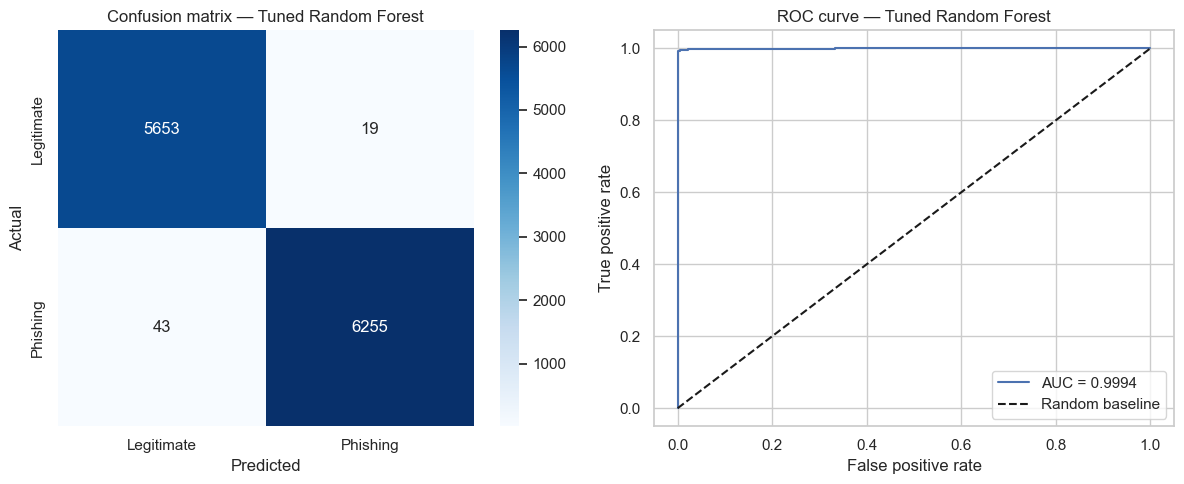

In [20]:
rf_tuned = RandomForestClassifier(bootstrap= True, ccp_alpha= 0.0, class_weight= None, criterion='entropy',
                                  max_depth= 15, max_features= 'sqrt', max_leaf_nodes= None, max_samples= None,
                                  min_impurity_decrease= 0.0, min_samples_leaf= 10, min_samples_split= 10,
                                  min_weight_fraction_leaf= 0.0, monotonic_cst= None, n_estimators= 500, n_jobs= -1,
                                  oob_score= False, random_state= 42, verbose= 0, warm_start= False)

rf_tuned.fit(x_train,y_train)

tuned_cv = cross_val_score(rf_tuned,x_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)

evaluate_model(rf_tuned,x_test,y_test,"Tuned Random Forest")

## 9. Hyperparameter tuning with Optuna
Optuna uses the same 5-fold splitter and tries `OPTUNA_TRIALS` (30) parameter combinations, each cross-validated 5 times. This also takes a very long time, so the search cell below is **commented out**. The best parameters it found were copied into the "Optuna Random Forest" cell that follows.

In [21]:
'''
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=100),
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
        "max_depth": trial.suggest_categorical("max_depth", [8, 12, 16, 24, None]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"])
    }
    model = RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1)
    scores = cross_val_score(model, x_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)
    return float(scores.mean())

study = optuna.create_study(direction="maximize",sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))

start = time.perf_counter()
study.optimize(objective, n_trials=OPTUNA_TRIALS, show_progress_bar=True)
optuna_fit_time = time.perf_counter() - start

rf_optuna = RandomForestClassifier(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1)

rf_optuna.fit(x_train, y_train)

print(f"Best 5-fold CV accuracy: {round(study.best_value,4)}")
print("Best parameters:", study.best_params)
print(f"Search time: {round(optuna_fit_time / 60,4)} minutes")
'''

'\ndef objective(trial):\n    params = {\n        "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=100),\n        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),\n        "max_depth": trial.suggest_categorical("max_depth", [8, 12, 16, 24, None]),\n        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),\n        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),\n        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"])\n    }\n    model = RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1)\n    scores = cross_val_score(model, x_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)\n    return float(scores.mean())\n\nstudy = optuna.create_study(direction="maximize",sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))\n\nstart = time.perf_counter()\nstudy.optimize(objective, n_trials=OPTUNA_TRIALS, show_progress_bar=True)\noptuna_fit_time = time.perf_counter() - star

**Search result:** **30** trials, best 5-fold CV accuracy **0.9935**. Best parameters: `n_estimators=200`, `criterion='entropy'`, `max_depth=24`, `min_samples_split=2`, `min_samples_leaf=1`, `max_features='sqrt'`. Search time: **58** minutes.

In [22]:
#rf_optuna.get_params()

Model: Optuna Random Forest

Accuracy: 0.9959

Balanced accuracy: 0.996

Precision: 0.9978

Recall: 0.9944

F1: 0.9961

ROC-AUC: 0.9994

Average precision: 0.9996

              precision    recall  f1-score   support

  Legitimate     0.9939    0.9975    0.9957      5672
    Phishing     0.9978    0.9944    0.9961      6298

    accuracy                         0.9959     11970
   macro avg     0.9958    0.9960    0.9959     11970
weighted avg     0.9959    0.9959    0.9959     11970



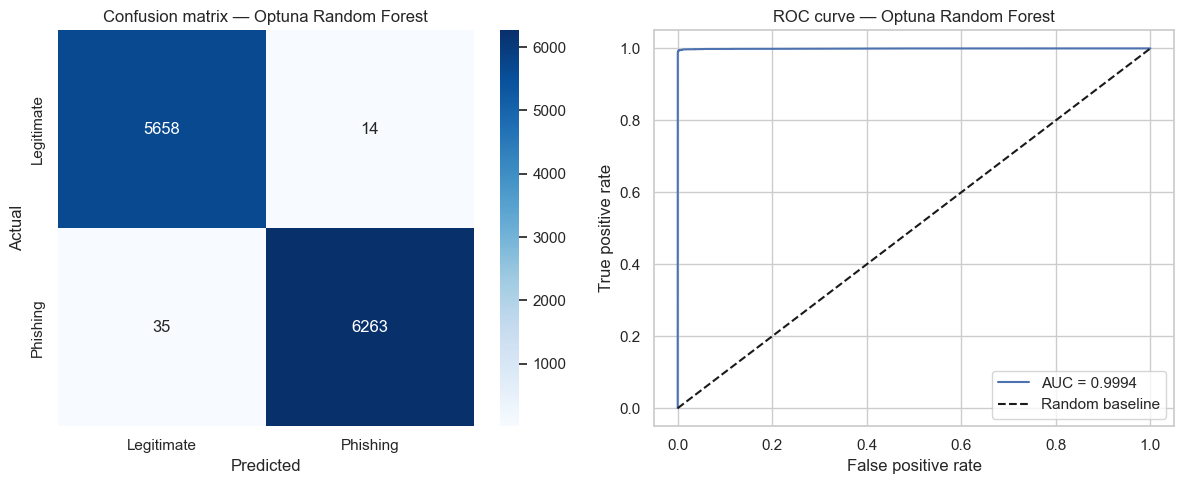

In [23]:
rf_optuna = RandomForestClassifier(bootstrap= True, ccp_alpha= 0.0, class_weight= None,
                                   criterion= 'entropy', max_depth= 24, max_features= 'sqrt', 
                                   max_leaf_nodes= None, max_samples= None, min_impurity_decrease= 0.0,
                                   min_samples_leaf= 1, min_samples_split= 2, min_weight_fraction_leaf= 0.0,
                                   monotonic_cst= None, n_estimators= 200, n_jobs= -1, oob_score= False,
                                   random_state= 42,verbose= 0,warm_start= False)

rf_optuna.fit(x_train,y_train)

optuna_cv = cross_val_score(rf_optuna,x_train, y_train, cv=cv, scoring="accuracy", n_jobs=1)

evaluate_model(rf_optuna,x_test,y_test,"Optuna Random Forest")

### Optuna optimization history
This plot needs the `study` object created by the Optuna search, so its cell is commented out too.

In [24]:
'''
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.title("Optuna optimization history")
plt.tight_layout()
plt.show()
'''

'\noptuna.visualization.matplotlib.plot_optimization_history(study)\nplt.title("Optuna optimization history")\nplt.tight_layout()\nplt.show()\n'

## 10. Compare models
The selection is based on mean 5-fold training CV accuracy, not test accuracy. The test metrics are reported for transparency only.

In [25]:
models = {
    "Baseline": rf_baseline,
    "GridSearchCV": rf_tuned,
    "Optuna": rf_optuna
}
cv_scores = {
    "Baseline": float(baseline_cv.mean()),
    "GridSearchCV": float(tuned_cv.mean()),
    "Optuna": float(optuna_cv.mean())
}

comparison = pd.DataFrame([
    {**get_metrics(model, x_test, y_test, name),
     "5-fold CV accuracy": cv_scores[name]}
    for name, model in models.items()
]).set_index("Model").sort_values("5-fold CV accuracy", ascending=False)

display(comparison.round(4))

,Accuracy,Balanced accuracy,Precision,Recall,F1,ROC-AUC,Average precision,5-fold CV accuracy
Model,,,,,,,,
Optuna,0.9959,0.9960,0.9978,0.9944,0.9961,0.9994,0.9996,0.9935
Baseline,0.9952,0.9952,0.9970,0.9938,0.9954,0.9992,0.9994,0.9931
GridSearchCV,0.9948,0.9949,0.9970,0.9932,0.9951,0.9994,0.9996,0.9921


**Insight:** all three models are almost identical, with test accuracy between 0.9948 and 0.9959 and ROC-AUC between 0.9992 and 0.9994. The three CV scores **(0.9921 to 0.9935)** differ by only **0.0014**, about twice the baseline's fold-to-fold variation (±0.0007). The tuned models were also chosen on these same folds, so their CV scores are slightly optimistic. In practice the three models perform the same, and tuning gave only a marginal gain.

In [26]:
best_name = comparison["5-fold CV accuracy"].idxmax()
print("Selected model by 5-fold CV accuracy:", best_name)
final_model = models[best_name]

Selected model by 5-fold CV accuracy: Optuna


### Compare confusion matrices, ROC curves and precision-recall curves

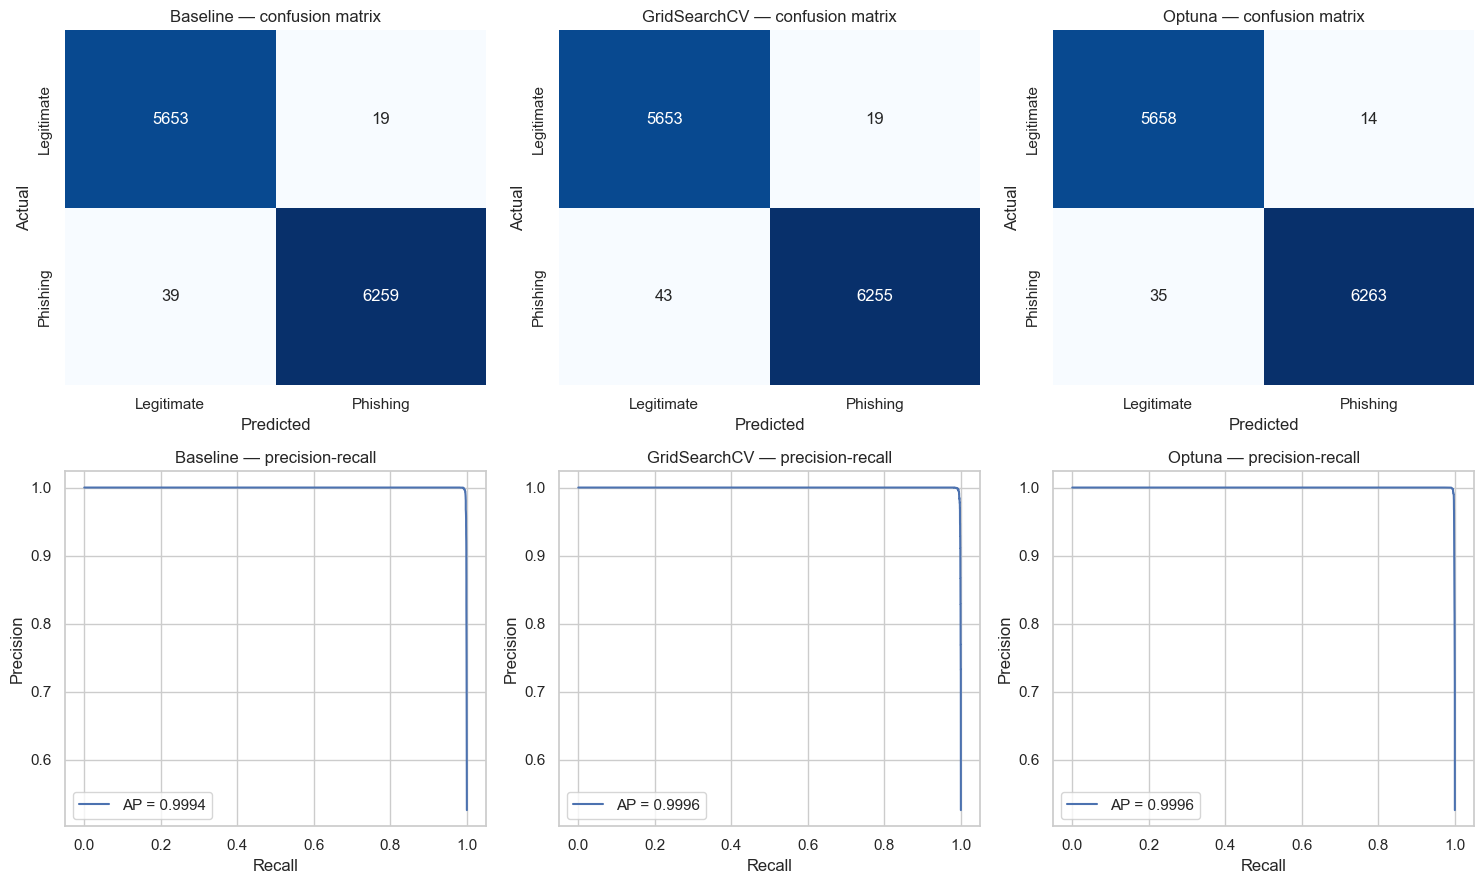

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for col, (name, model) in enumerate(models.items()):
    pred = model.predict(x_test)
    prob = model.predict_proba(x_test)[:, 1]
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d",cmap="Blues", cbar=False, xticklabels=LABEL_NAMES,yticklabels=LABEL_NAMES, ax=axes[0, col])
    axes[0, col].set_title(f"{name} — confusion matrix")
    axes[0, col].set_xlabel("Predicted")
    axes[0, col].set_ylabel("Actual")

    precision, recall, _ = precision_recall_curve(y_test, prob, pos_label=1)
    ap = average_precision_score(y_test, prob)
    axes[1, col].plot(recall, precision, label=f"AP = {ap:.4f}")
    axes[1, col].set_title(f"{name} — precision-recall")
    axes[1, col].set_xlabel("Recall")
    axes[1, col].set_ylabel("Precision")
    axes[1, col].legend()
plt.tight_layout()
plt.show()

**Insight:** errors are very few for every model: **58** for the baseline (19 false alarms and 39 missed phishing sites), **62** for GridSearchCV (19 and 43) and **49** for Optuna (14 and 35), out of 11,970 test samples. All three miss more phishing sites than they falsely flag. The precision-recall curves stay close to **1.0** until recall is almost **1.0** (average precision **0.9994 to 0.9996**).

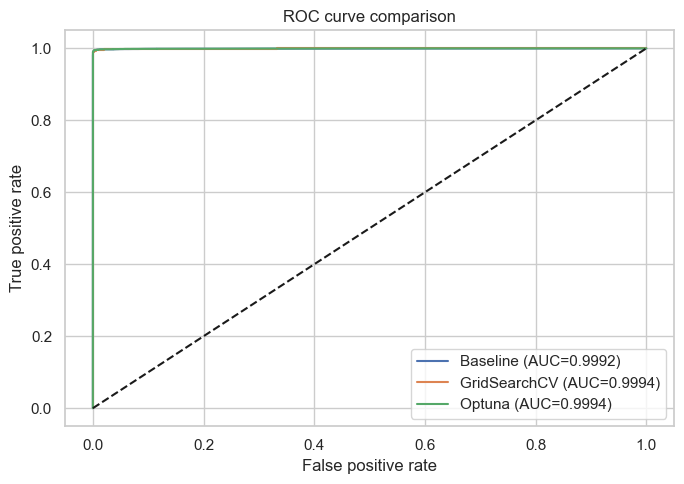

In [28]:
plt.figure(figsize=(7, 5))
for name, model in models.items():
    prob = model.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob, pos_label=1)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve comparison")
plt.legend()
plt.tight_layout()
plt.show()

**Insight:** the three ROC curves lie on top of each other and hug the top-left corner **(AUC 0.9992 to 0.9994)**. The models rank almost every phishing site above every legitimate one, and the tiny AUC differences are not meaningful.

## 11. Threshold analysis
A threshold other than 0.5 may be useful when false positives (legitimate sites flagged as phishing) and false negatives (missed phishing sites) have different costs. The table below uses **out-of-fold predictions on the training set**, where each training row is predicted by a model that did not see it, so the test set is not used to choose the threshold. The counts are therefore out of 47,875 training rows, not the 11,970 test rows.

In [29]:
final_prob = final_model.predict_proba(x_test)[:, 1]
oof_prob = cross_val_predict(final_model, x_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]

threshold_rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    pred = (oof_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0),
        "False positives": fp,
        "False negatives": fn
    })

display(pd.DataFrame(threshold_rows).round(4))

,Threshold,Precision,Recall,F1,False positives,False negatives
0,0.2,0.9826,0.9961,0.9893,445,98
1,0.3,0.9910,0.9945,0.9927,228,138
2,0.4,0.9948,0.9928,0.9938,130,181
3,0.5,0.9967,0.9909,0.9938,83,229
4,0.6,0.9984,0.9882,0.9933,41,297
5,0.7,0.9992,0.9844,0.9917,21,392
6,0.8,0.9998,0.9777,0.9886,6,562


**Insight:** lowering the threshold from 0.5 to 0.3 cuts the missed phishing sites from 229 to 138 but raises the false alarms from 83 to 228. Raising it to 0.7 cuts the false alarms to 21 but misses 392 phishing sites. F1 is highest and almost flat between 0.4 and 0.5 (0.9938), so 0.5 is a good default. Choose a lower threshold only if missing a phishing site is clearly worse than a false alarm.

## 12. Learning curve
A learning curve can help indicate whether adding training data may improve performance. It uses the same 5-fold cross-validation strategy.

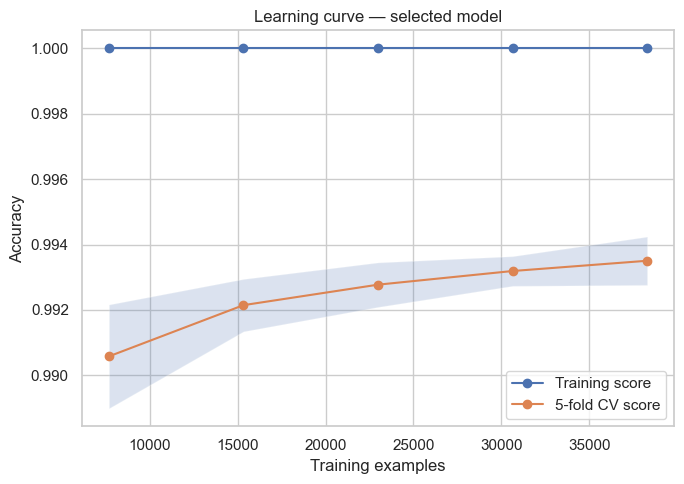

In [30]:
sizes, train_scores, valid_scores = learning_curve(RandomForestClassifier(**final_model.get_params()), x_train, y_train, cv=cv, scoring="accuracy", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=1)

plt.figure(figsize=(7, 5))
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="Training score")
plt.plot(sizes, valid_scores.mean(axis=1), "o-", label="5-fold CV score")
plt.fill_between(sizes, valid_scores.mean(axis=1) - valid_scores.std(axis=1),valid_scores.mean(axis=1) + valid_scores.std(axis=1), alpha=0.2)
plt.xlabel("Training examples")
plt.ylabel("Accuracy")
plt.title("Learning curve — selected model")
plt.legend()
plt.tight_layout()
plt.show()

**Insight:** the training score stays at 1.0, which is normal for a deep Random Forest because it memorizes the training data, so the gap to the CV score (about 0.0065) is not a problem by itself. The CV score rises from about 0.9906 with 7,600 samples to 0.9935 with 38,000, and the curve is flattening, so more data would help only a little.

## 13. Feature importance and calibration

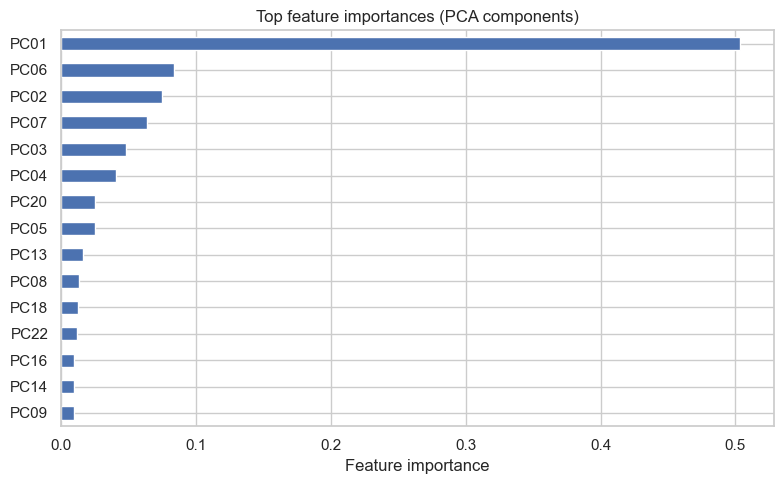

In [31]:
importances = pd.Series(final_model.feature_importances_, index=x_train.columns).sort_values().tail(15)

plt.figure(figsize=(8, 5))
importances.sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Top feature importances (PCA components)")
plt.tight_layout()
plt.show()

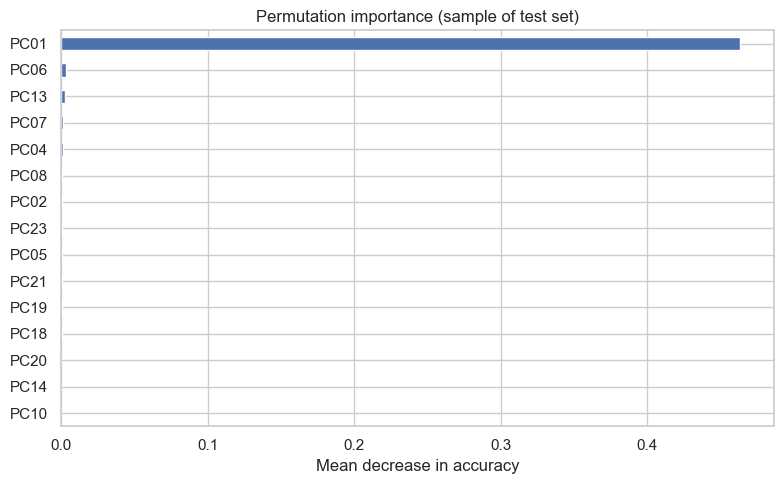

In [32]:
sample_n = min(3000, len(x_test))
x_sample = x_test.sample(sample_n, random_state=RANDOM_STATE)
y_sample = y_test.loc[x_sample.index]
perm = permutation_importance(final_model, x_sample, y_sample,n_repeats=5, random_state=RANDOM_STATE, scoring="accuracy", n_jobs=-1)

perm_importance = pd.Series(perm.importances_mean, index=x_train.columns).sort_values().tail(15)
plt.figure(figsize=(8, 5))
perm_importance.sort_values().plot(kind="barh")
plt.xlabel("Mean decrease in accuracy")
plt.title("Permutation importance (sample of test set)")
plt.tight_layout()
plt.show()

**Insight (importance):** one component dominates. PC01 holds about half of the impurity importance (0.50), far above PC06 (0.08) and PC02 (0.07). Permutation importance agrees even more strongly: shuffling PC01 alone drops test accuracy by about 0.45, to roughly 0.55, while shuffling any other component changes it by less than 0.01. Almost all of the model's skill comes from a single component. Since components are PCA mixtures, we cannot say which original URL features make up PC01 without its loadings.

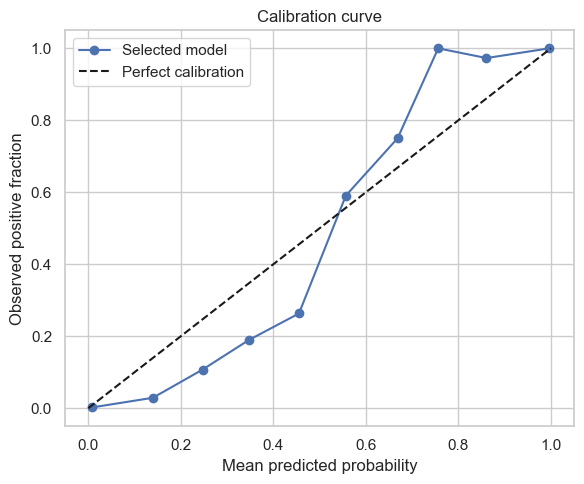

In [33]:
prob_true, prob_pred = calibration_curve(y_test, final_prob, n_bins=10, strategy="uniform")
plt.figure(figsize=(6, 5))
plt.plot(prob_pred, prob_true, "o-", label="Selected model")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Calibration curve")
plt.legend()
plt.tight_layout()
plt.show()

**Insight (calibration):** the curve is S-shaped. For predicted probabilities of about 0.1 to 0.5, the real phishing rate is lower than predicted (predicted 0.45, observed about 0.26). For 0.65 to 0.9 it is higher (predicted 0.75, observed 1.0). This is typical for Random Forests, because averaging many trees pulls probabilities away from 0 and 1. The model is accurate at both ends, so its probabilities are best used to rank and threshold, not read as exact percentages. If exact probabilities are needed, calibrate the model (for example with `CalibratedClassifierCV`).

## 14. Final held-out test evaluation

Model: Selected model: Optuna

Accuracy: 0.9959

Balanced accuracy: 0.996

Precision: 0.9978

Recall: 0.9944

F1: 0.9961

ROC-AUC: 0.9994

Average precision: 0.9996

              precision    recall  f1-score   support

  Legitimate     0.9939    0.9975    0.9957      5672
    Phishing     0.9978    0.9944    0.9961      6298

    accuracy                         0.9959     11970
   macro avg     0.9958    0.9960    0.9959     11970
weighted avg     0.9959    0.9959    0.9959     11970



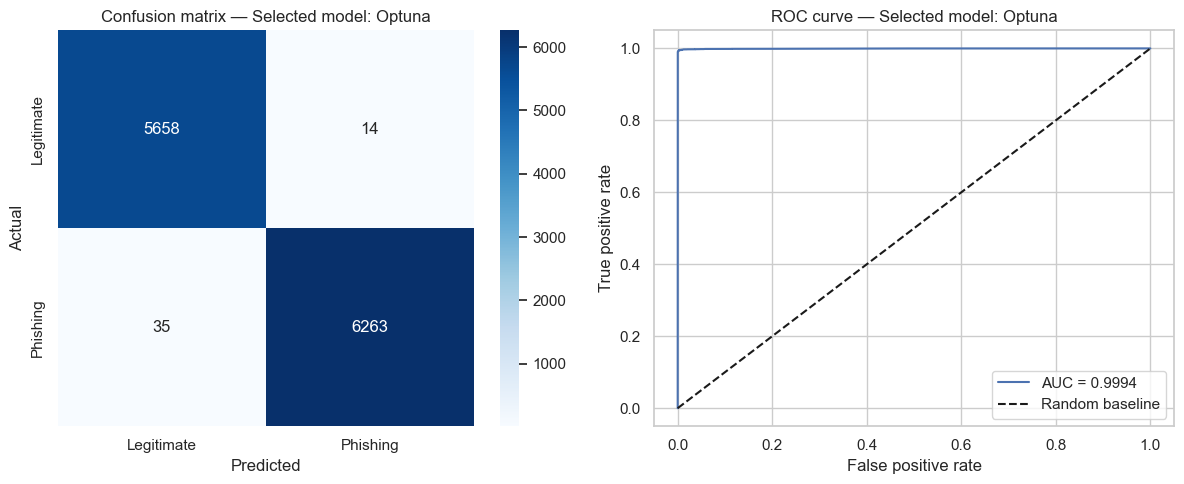

In [34]:
evaluate_model(final_model, x_test, y_test, f"Selected model: {best_name}")

**Insight:** the final held-out results match the comparison table: accuracy **0.9959**, balanced accuracy **0.996**, F1 **0.9961** and ROC-AUC **0.9994**. Both classes are handled equally well (F1 **0.9957** for Legitimate and **0.9961** for Phishing).

## 15. Save the model, parameters, metrics and metadata
Because the input features are already PCA-transformed, the saved classifier expects the same transformed feature columns. To predict from raw website data, also bundle the exact fitted preprocessing steps from the preprocessing workflow.
The metadata also records the scikit-learn version, because a saved model may not load correctly under a different version.

In [35]:
model_path = MODEL_DIR / "random_forest.joblib"
params_path = MODEL_DIR / "best_random_forest_params.json"
metrics_path = MODEL_DIR / "model_metrics.json"
metadata_path = MODEL_DIR / "model_metadata.json"

joblib.dump(final_model, model_path)

with open(params_path, "w", encoding="utf-8") as f:
    json.dump(final_model.get_params(), f, indent=2, default=str)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(comparison.reset_index().to_dict(orient="records"), f, indent=2, default=str)

metadata = {
    "selected_model": best_name,
    "target_column": TARGET,
    "class_mapping": {"0": "Legitimate", "1": "Phishing"},
    "feature_columns": list(x_train.columns),
    "feature_count": int(x_train.shape[1]),
    "sklearn_version": sklearn.__version__,
    "cv": {"type": "StratifiedKFold", "n_splits": N_SPLITS,
           "shuffle": True, "random_state": RANDOM_STATE},
    "note": "Model expects PCA-transformed features in the recorded feature order."
}
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", model_path)
print("Saved parameters:", params_path)
print("Saved metrics:", metrics_path)
print("Saved metadata:", metadata_path)

Saved model: c:\Users\LENOVO\OneDrive\Desktop\models\random_forest.joblib
Saved parameters: c:\Users\LENOVO\OneDrive\Desktop\models\best_random_forest_params.json
Saved metrics: c:\Users\LENOVO\OneDrive\Desktop\models\model_metrics.json
Saved metadata: c:\Users\LENOVO\OneDrive\Desktop\models\model_metadata.json


## 16. Reload and verify

In [36]:
if not model_path.is_file():
    raise FileNotFoundError(f"Model was not saved: {model_path}")

loaded_model = joblib.load(model_path)
original_predictions = final_model.predict(x_test)
loaded_predictions = loaded_model.predict(x_test)

if not np.array_equal(original_predictions, loaded_predictions):
    raise AssertionError("Reloaded model predictions differ from the original model.")

print("Reload check passed: predictions match exactly.")
print(f"Reloaded-model test accuracy: {accuracy_score(y_test, loaded_predictions):.4f}")

Reload check passed: predictions match exactly.
Reloaded-model test accuracy: 0.9959


## 17. Conclusion and limitations

### Why are the scores so high?
Test accuracy is about 99.5% for every model, even the untuned baseline. Several signs show that this comes from the data being easy to separate, not from an especially clever model:
- **Tuning changed almost nothing.** Baseline, GridSearchCV and Optuna are within about 0.001 of each other.
- **One component does almost all the work.** Shuffling PC01 alone drops accuracy by about 0.45.
- **The learning curve is almost flat.** With only 7,600 training samples the CV accuracy is already about 0.9906.
- **The two classes come from different sources** (phishing URLs from PhishTank, legitimate URLs from Tranco). Features such as URL path length and token count can differ systematically between the two lists; in the earlier feature analysis, `path_length` alone gave a test AUC of about 0.99. The model may therefore partly learn which list a URL came from.

This means the scores probably describe how easy this dataset is, and they may not carry over to phishing URLs collected from other sources.

### Key findings
- **Selected model: Optuna Random Forest.** It has the best 5-fold CV accuracy (0.9935) and the best test results: accuracy 0.9959, F1 0.9961, ROC-AUC 0.9994. It was chosen using cross-validation on the training data, not the test set.
- **All three models are almost identical.** Test accuracy goes from 0.9948 (GridSearchCV) to 0.9959 (Optuna), a gap of about 13 samples out of 11,970. The CV gap between Optuna and the baseline (0.9935 vs 0.9931) is smaller than the baseline's own fold-to-fold variation (±0.0007), so tuning gave only a marginal gain.
- **The grid search was slightly worse than the baseline** (CV 0.9921 vs 0.9931). Its grid forced shallow, heavily restricted trees (`max_depth` up to 15, `min_samples_leaf` of at least 10). Optuna's best settings (`max_depth=24`, `min_samples_leaf=1`, `min_samples_split=2`) are close to the defaults, which suggests this data prefers deep, unrestricted trees.
- **Errors are few and slightly lean towards missed phishing sites.** Precision (0.9978) is higher than recall (0.9944). At the 0.5 threshold, the model misses about 35 phishing sites and wrongly flags about 14 legitimate ones.
- **The threshold is a trade-off.** Lower thresholds miss fewer phishing sites but raise false alarms, and higher thresholds do the opposite. If a missed phishing site is worse than a false alarm, a threshold below 0.5 is worth considering. The table in section 11 shows the exact numbers.
- **The model, its parameters, metrics and metadata were saved** in the `models` folder, and the reloaded model gave exactly the same predictions.

### Limitations and checks before deployment
- **Duplicates:** the training set has 4,540 duplicate rows (about 9.5%), and 70 identical feature vectors appear in both train and test. They were kept on purpose (see the note in section 4). The test accuracy is slightly higher than the CV accuracy for all three models, so there is no sign that they inflate the results, but confirming on fresh data is still worthwhile.
- **Newer data:** phishing sites change over time, so the model should also be tested on fresh, newer samples.
- **Raw data:** the saved model only accepts PCA-transformed features. To predict on raw website data, the same fitted scaler and PCA must be applied first.
- **Alert threshold:** choose it from the real cost of false positives and false negatives, ideally using validation data rather than the test set.
- **Source bias:** legitimate and phishing URLs come from different lists, so the model may learn the source instead of phishing behaviour. Test it on URLs collected from other sources.